# 34 — History Dependence & Paired Statistical Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 9 (Fresh Held-Out Scenario Generation & Pre-Registered Pilot Evaluation)  
**Status:** `Pre-registered held-out pilot analysis — exploratory, not confirmatory.`  

### Objectives:
1. Evaluate paired comparisons across conditions (B0 vs B1, B2, B3, B4).
2. Report McNemar tests, Wilcoxon signed-rank tests, bootstrap CIs, and Holm-Bonferroni corrections.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
comp_path = os.path.join(repo_root, "results", "heldout_pilot", "paired_comparisons.json")
with open(comp_path) as f:
    paired = json.load(f)

print(f"{'Policy':25s} | {'Pair':10s} | Discordant | Diff (%) | McNemar p | Wilcoxon p | Holm-Bonf p")
print("-" * 88)
for c in paired["comparisons"]:
    print(f"{c['policy_id']:25s} | {c['pair']:10s} | {c['discordant_scenarios']:2d} / {c['valid_pairs']:2d}    | {c['mean_signed_diff']*100:+6.1f}%  | {c['mcnemar_p_value']:9.4f} | {c['wilcoxon_p_value']:10.4f} | {c['holm_bonferroni_p_value']:10.4f}")


Policy                    | Pair       | Discordant | Diff (%) | McNemar p | Wilcoxon p | Holm-Bonf p
----------------------------------------------------------------------------------------
reactive_mlp              | B0_vs_B1   |  0 / 45    |   +0.0%  |    1.0000 |     0.9893 |     1.0000
reactive_mlp              | B0_vs_B2   |  0 / 45    |   +0.0%  |    1.0000 |     0.6893 |     1.0000
reactive_mlp              | B0_vs_B3   |  0 / 45    |   +0.0%  |    1.0000 |     0.3016 |     1.0000
reactive_mlp              | B0_vs_B4   |  0 / 45    |   +0.0%  |    1.0000 |     0.1824 |     1.0000
reactive_mlp              | B1_vs_B4   |  0 / 45    |   +0.0%  |    1.0000 |     0.2439 |     1.0000
reactive_mlp              | B2_vs_B4   |  0 / 45    |   +0.0%  |    1.0000 |     0.2799 |     1.0000
reactive_mlp              | B3_vs_B4   |  0 / 45    |   +0.0%  |    1.0000 |     0.2578 |     1.0000
history_gru               | B0_vs_B1   |  0 / 45    |   +0.0%  |    1.0000 |     0.6721 |     1.0000
h

### History Dependence Score and Uncertainty Intervals (Figures 69 to 71)

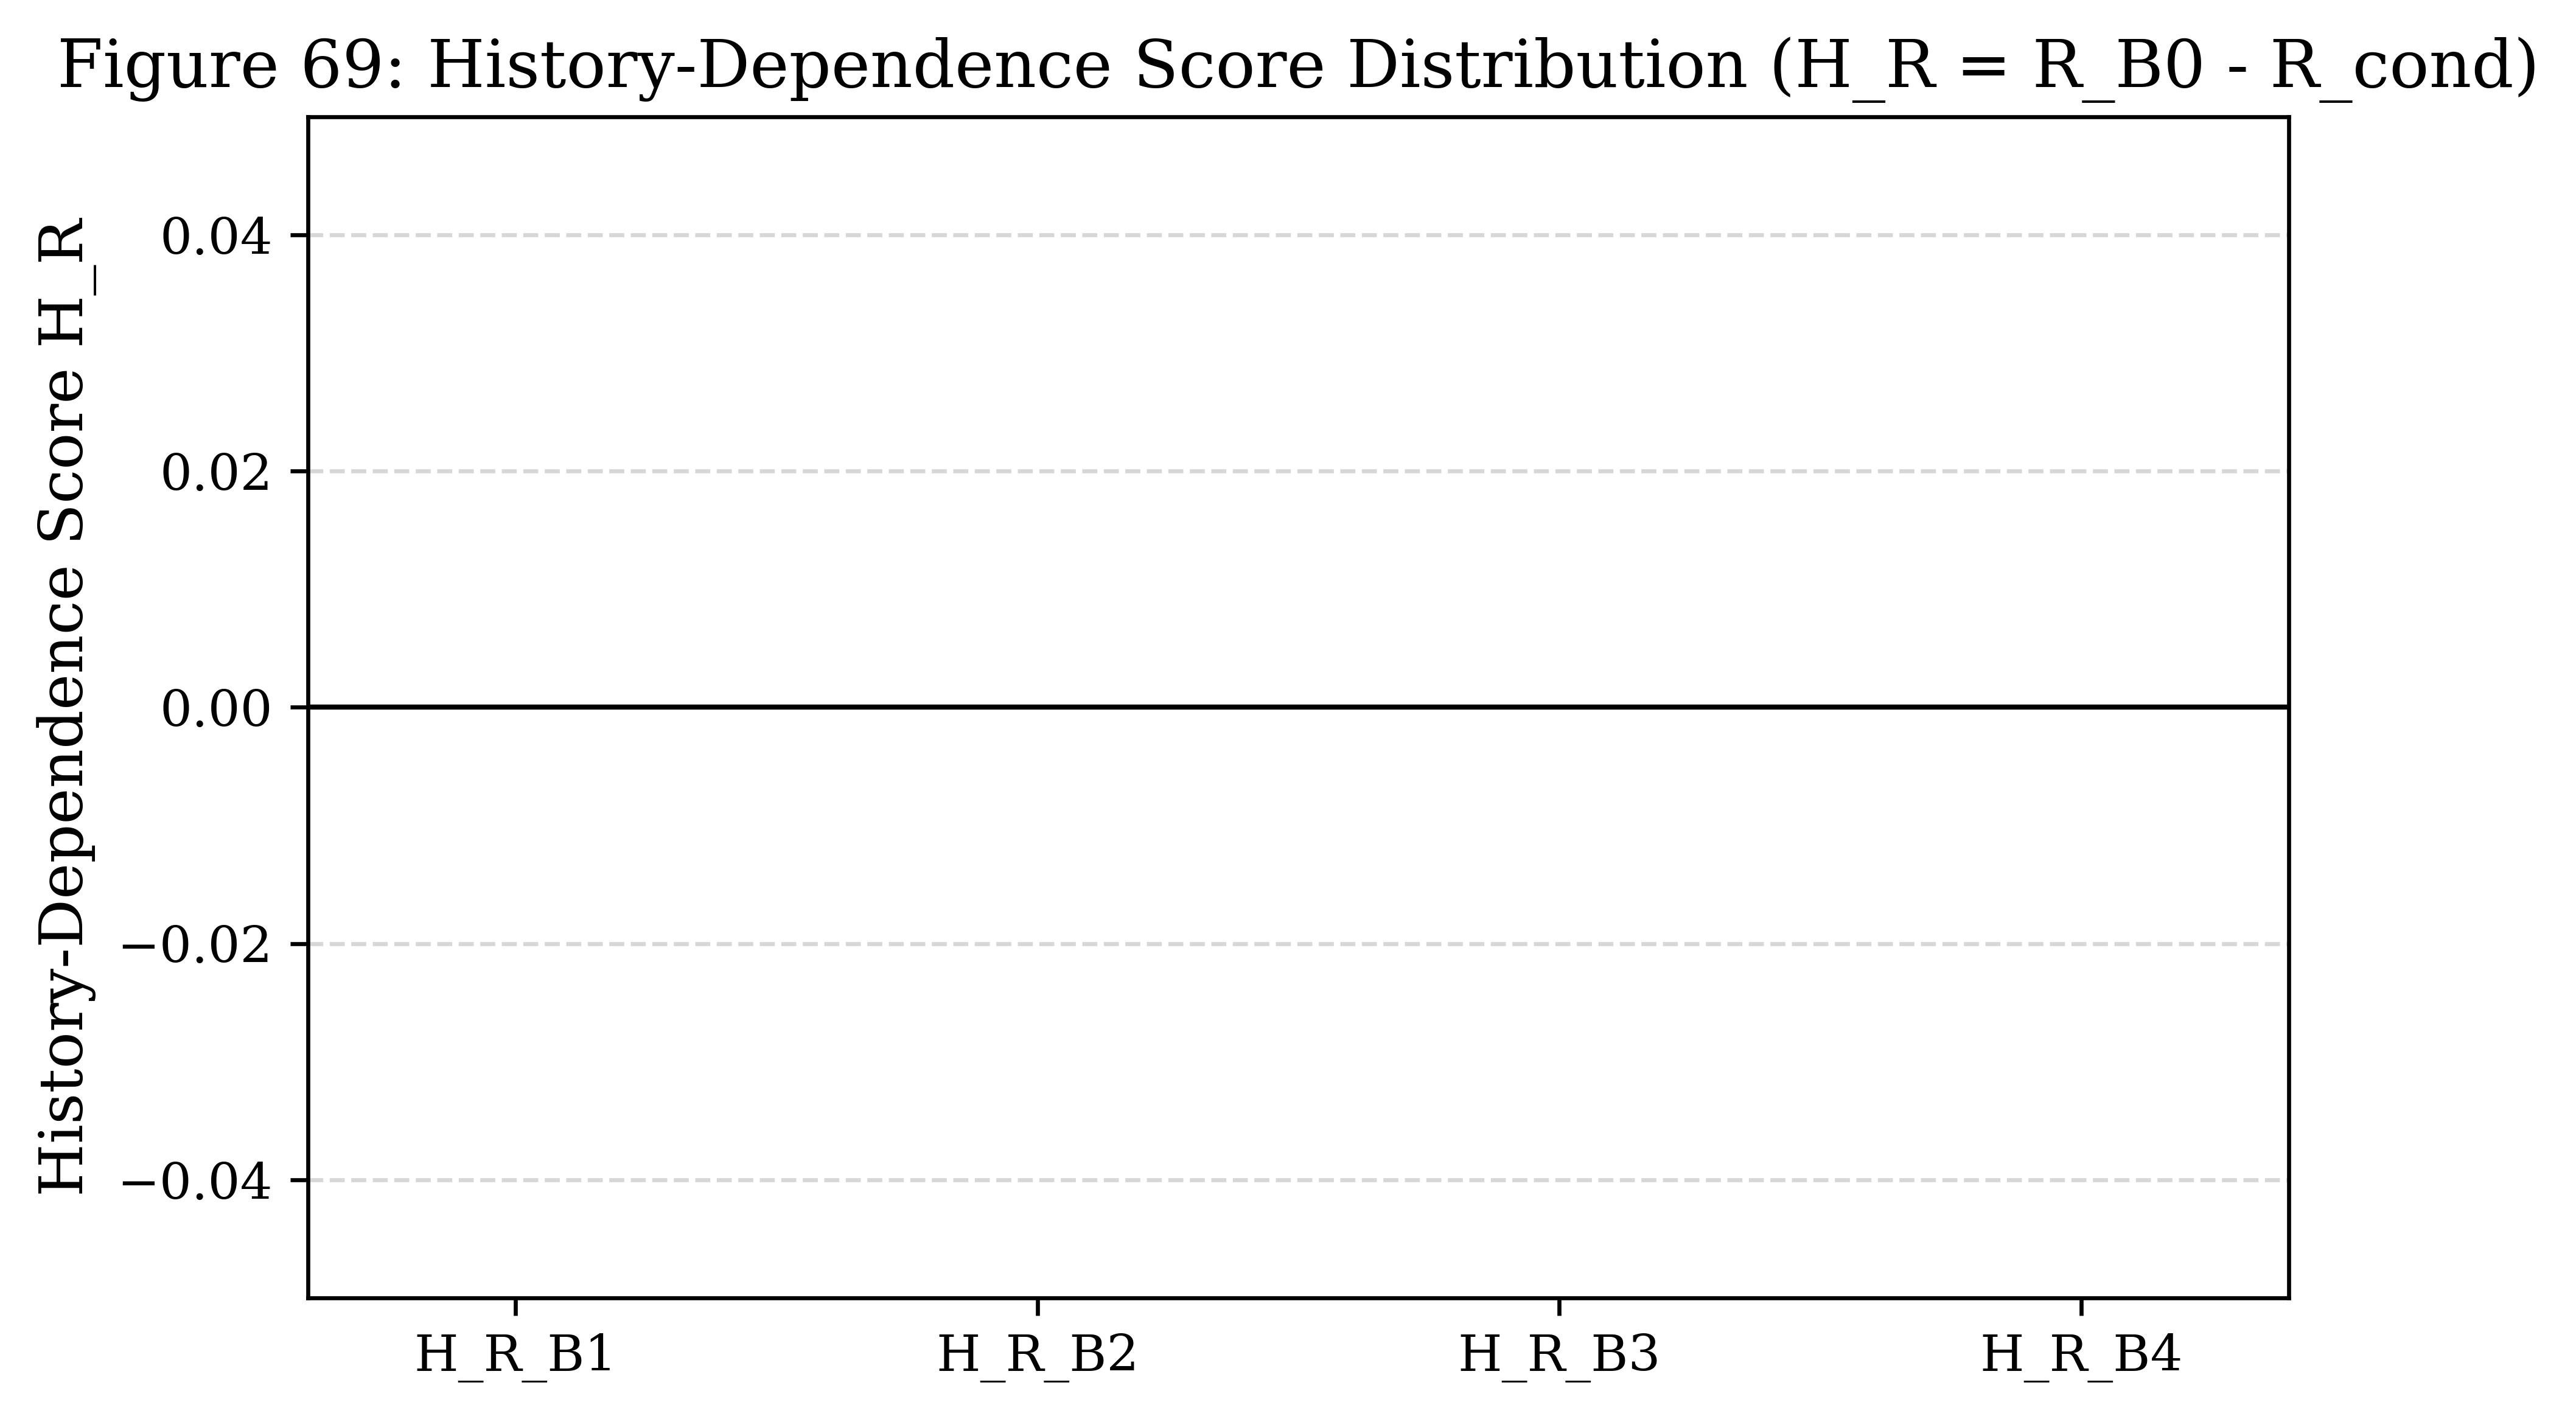

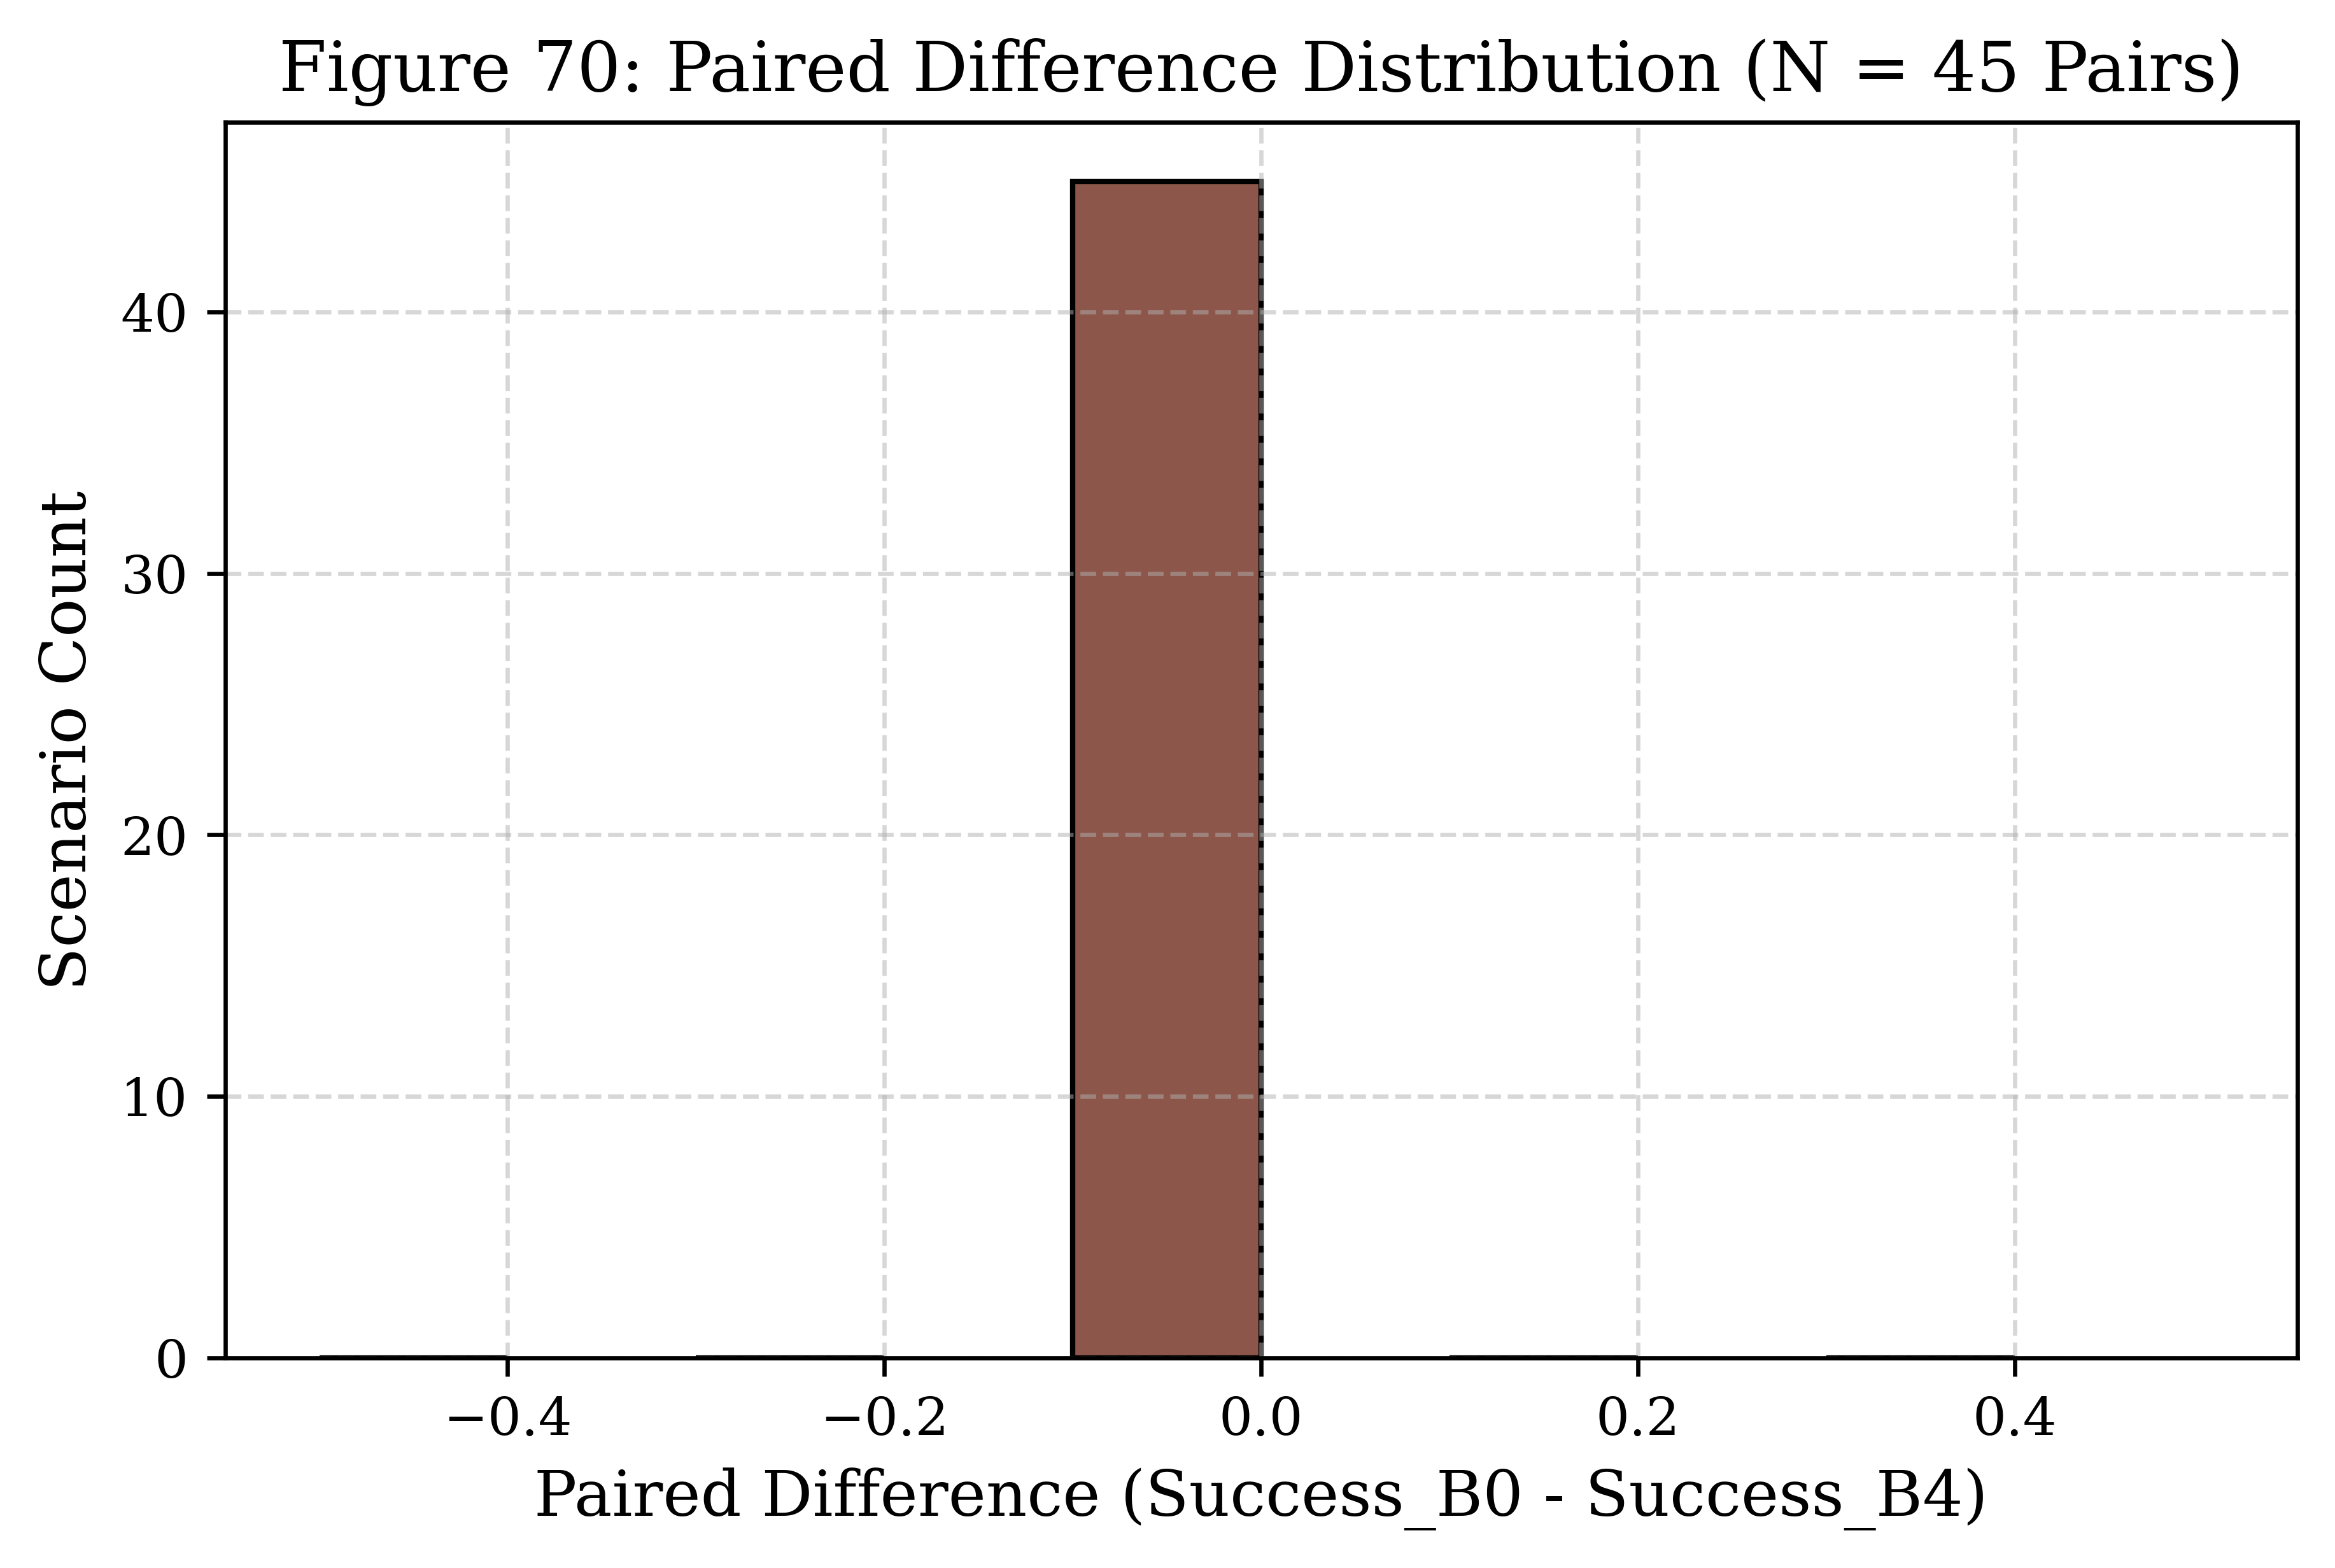

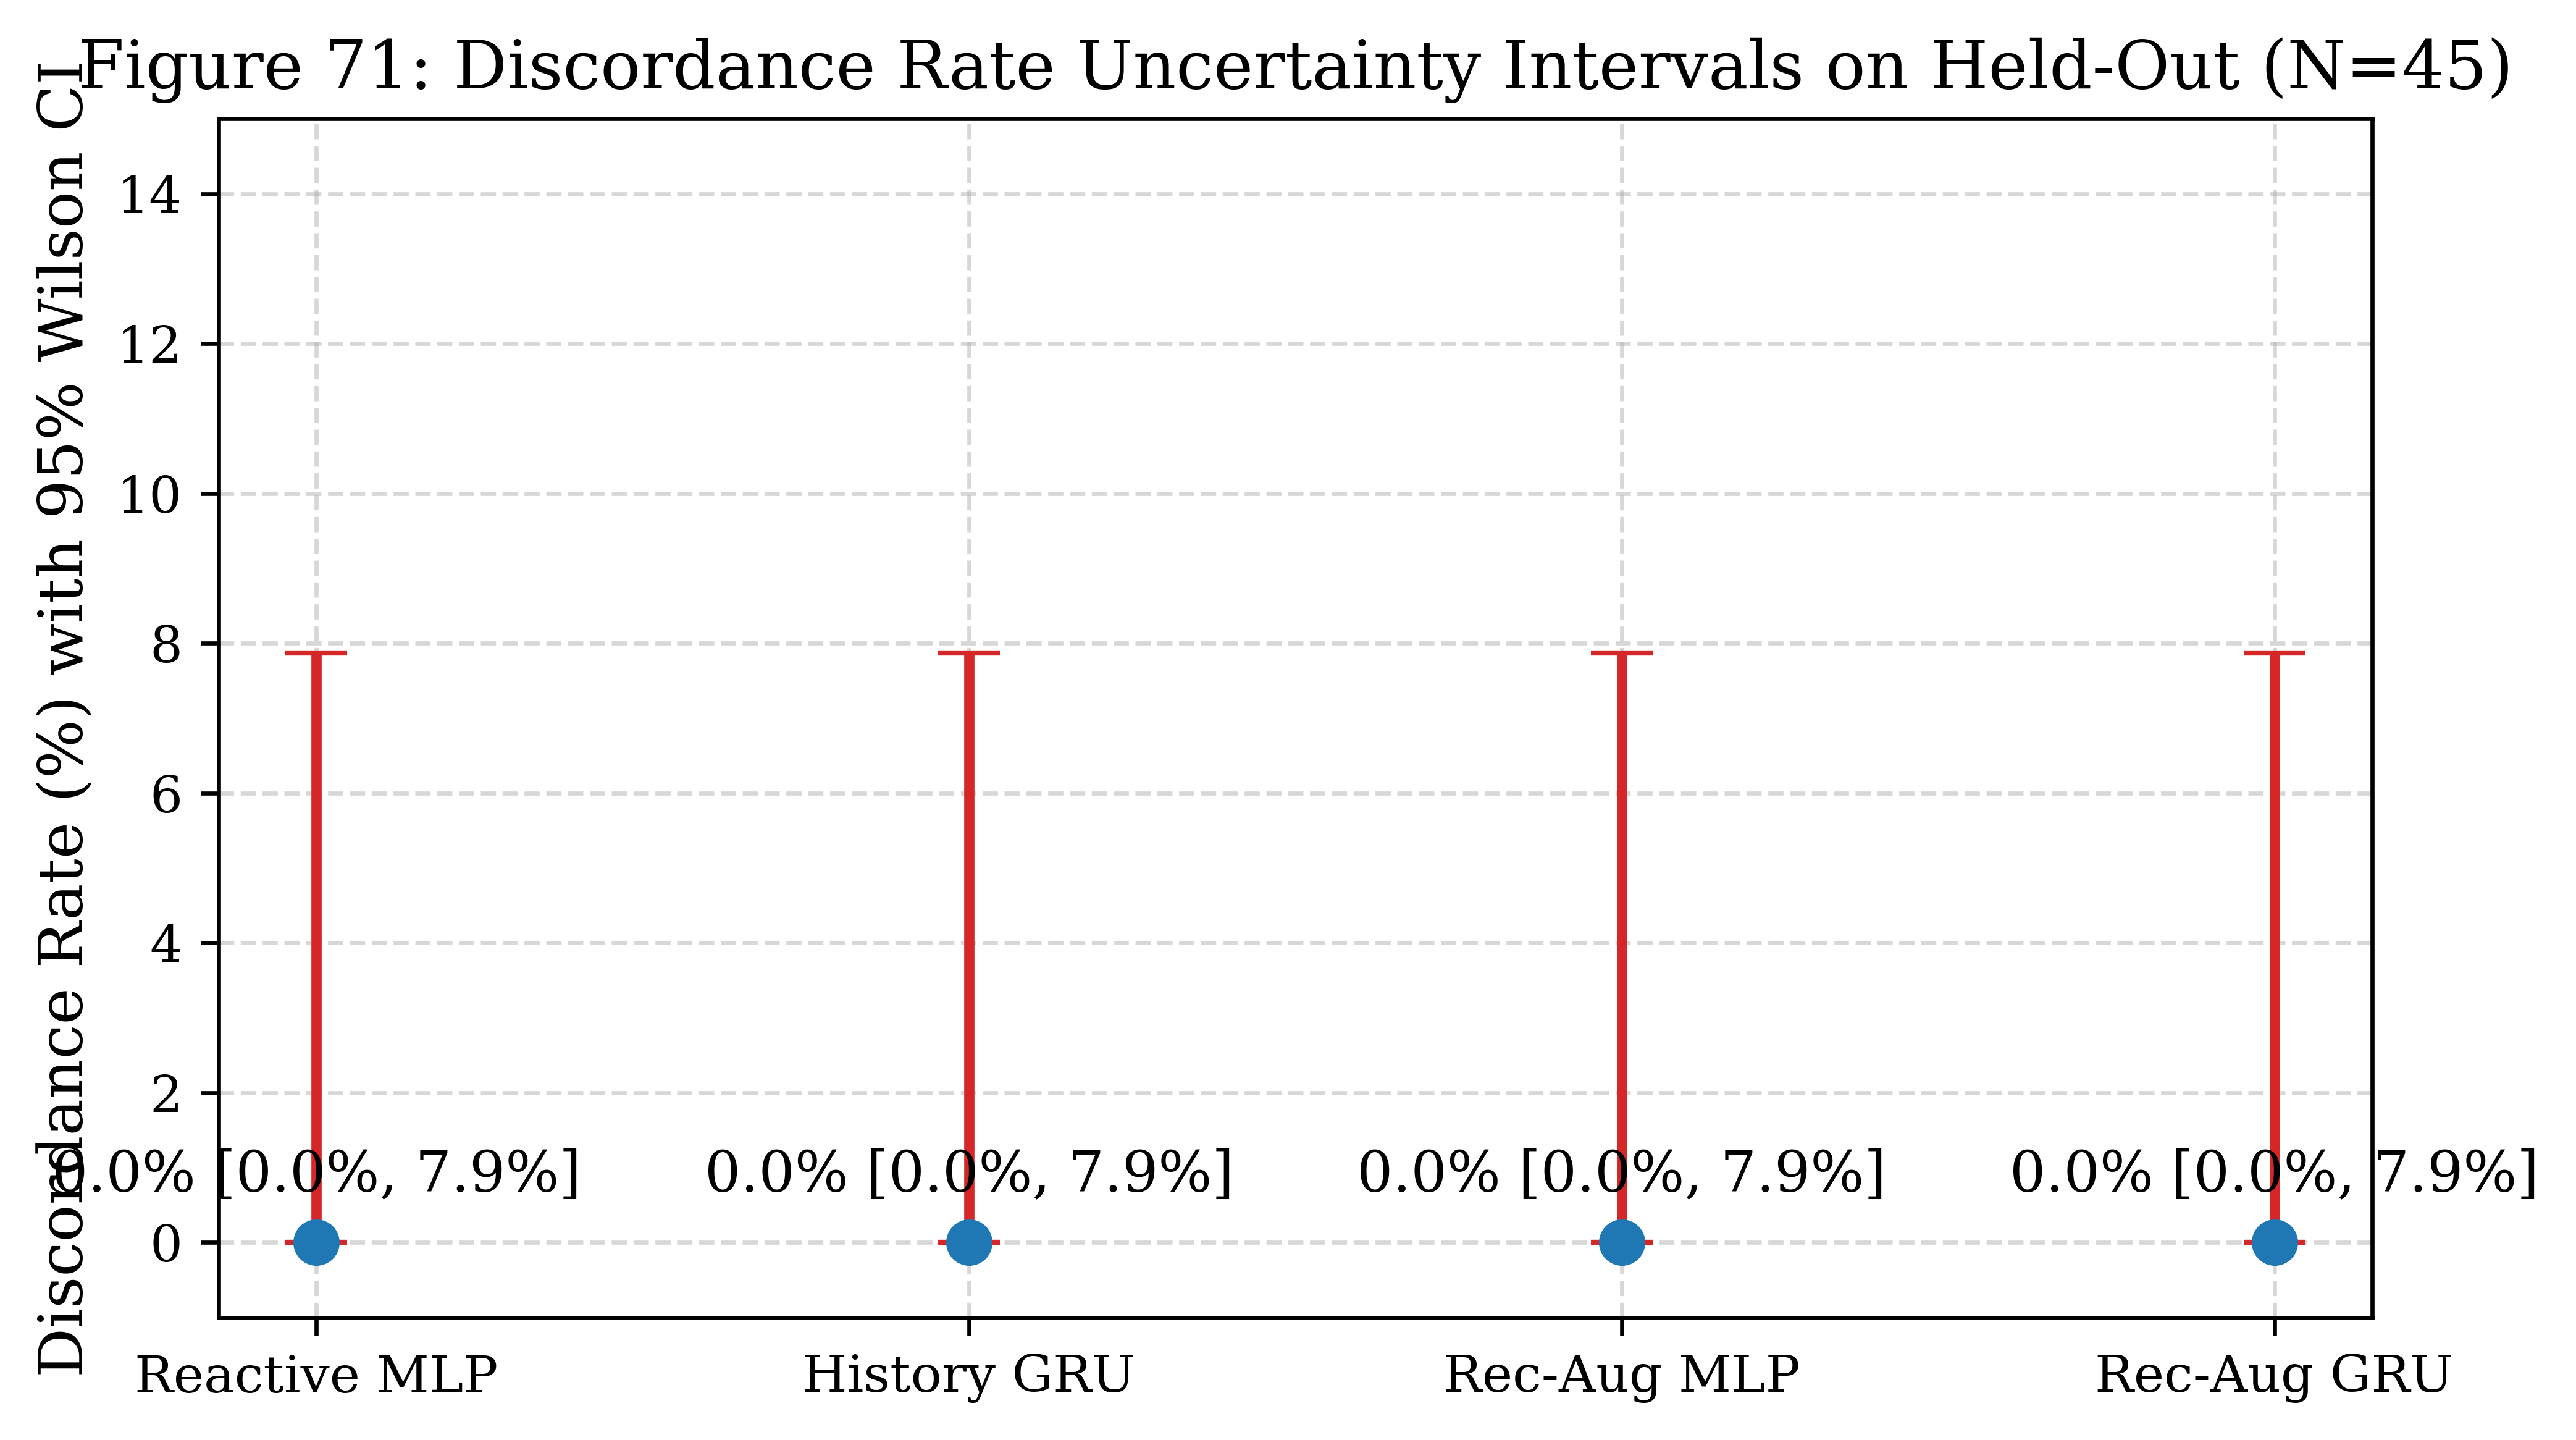

In [2]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig69_history_dependence_score_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig70_paired_difference_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig71_bootstrap_ci_paired_differences.png")))
